# 02 · Modeling: Feature Engineering, Pipeline, Model Selection, Evaluasi

Tahap **4–10** dari workflow analisis:

4. Feature selection · 5. Normalisasi / transformasi (`ColumnTransformer`) · 6. Konstruksi model (`Pipeline`)
· 7. Model selection · 8. Evaluasi · 9. Visualisasi hasil · 10. Optimalisasi performa

**Aturan:** tanpa neural network dan tanpa LLM; `SEED = 42`; validasi `StratifiedKFold` 5 fold.
Semua langkah memakai pipeline scikit-learn dari `scripts/`:

```
Pipeline([
    ('target_features', LocationTargetEncoder()),       # fitur berbasis label, cross-fitting (fold-safe)
    ('columns', ColumnTransformer([...])),              # passthrough/OrdinalEncoder atau scaler/OneHot
    ('model', ClassWeightedClassifier(estimator)),      # argmax(proba x bobot kelas) untuk Macro F1
])
```

Karena `LocationTargetEncoder.fit_transform` memakai cross-fitting internal, `cross_val_predict` atas pipeline
penuh memberi skor OOF yang jujur: label baris validasi tidak pernah masuk ke fitur mana pun.

In [1]:
import sys, os, time, warnings, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

from scripts.preprocess import SEED, GRADES, CAT_COLS, load_data, add_unsupervised_features

np.random.seed(SEED)
DATA_DIR = '../data'
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)
T0 = time.time()

# Palet: rampa biru berurutan untuk grade 1 -> 5 (target ordinal)
GRADE_COLORS = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']
ACCENT, ACCENT2 = '#2a78d6', '#eb6834'
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'font.size': 10})

def savefig(name):
    # simpan figur ke reports/figures lalu tampilkan
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight'); plt.show()

import joblib
import lightgbm as lgb
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from scripts.feature_engineering import LocationTargetEncoder
from scripts.train import (LGBM_PARAMS, build_pipeline, build_preprocessor, macro_f1, fit_class_weights,
                           crossfit_macro_f1, make_folds, oof_proba, tune_n_estimators)
MODEL_DIR = '../models'; os.makedirs(MODEL_DIR, exist_ok=True)
N_JOBS = os.cpu_count()

def bootstrap_se(y_true, y_pred, n, B=200):
    # SE Macro F1 lewat bootstrap (dasar gerbang derau, skill noise-floor)
    rng = np.random.default_rng(SEED)
    return np.std([macro_f1(y_true[i], y_pred[i]) for i in (rng.integers(0, len(y_true), n) for _ in range(B))], ddof=1)

In [2]:
train, test, y = load_data(DATA_DIR)
if os.environ.get('SMOKE'):   # uji asap cepat saja, tidak dipakai untuk hasil
    keep = np.random.default_rng(SEED).choice(len(train), 40000, replace=False)
    train, y = train.iloc[keep].reset_index(drop=True), y[keep]
X, X_test = add_unsupervised_features(train, test)
FOLDS = make_folds(X, y)
print(X.shape, X_test.shape, f'{time.time()-T0:.0f}s')

(533465, 48) (228629, 48) 67s


## 4. Feature Selection

Fitur kandidat (lihat docstring `scripts/feature_engineering.py`):
- **tanpa label**: struktur `building_id`, cleaning umur, rasio, interaksi material×fondasi×atap, count encoding, komposisi bangunan per klaster;
- **berbasis label** (fold-safe): target encoding bertingkat distrik → … → klaster, grade tetangga ID, kerentanan struktural `vuln`, residu lokasi `grade − vuln`, dan interaksi lokasi × material.

Seleksi: LightGBM cepat di fold 0 → *gain importance* → buang fitur dengan gain < 0,1%. Seleksi hanya diterima
kalau Macro F1 tidak turun melebihi gerbang derau (2 × SE bootstrap).

In [3]:
a, b = FOLDS[0]
enc = LocationTargetEncoder()
Xa = enc.fit_transform(X.iloc[a], y[a]); Xb = enc.transform(X.iloc[b])
ct = build_preprocessor('tree').fit(Xa)
Za, Zb = ct.transform(Xa), ct.transform(Xb)
ALL_FEATS = list(Za.columns)

def quick_lgb(cols):
    m = lgb.LGBMClassifier(**{**LGBM_PARAMS, 'n_estimators': 3000, 'learning_rate': 0.1, 'n_jobs': N_JOBS})
    m.fit(Za[cols], y[a], eval_set=[(Zb[cols], y[b])], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m, macro_f1(y[b], m.predict(Zb[cols]))

m_all, s_all = quick_lgb(ALL_FEATS)
imp = pd.Series(m_all.booster_.feature_importance('gain'), ALL_FEATS)
imp = (imp / imp.sum()).sort_values(ascending=False)
SEL_FEATS = [c for c in imp.index if imp[c] >= 0.001]
m_sel, s_sel = quick_lgb(SEL_FEATS)
gate_fold = 2 * bootstrap_se(y[b], m_all.predict(Zb[ALL_FEATS]), len(b), B=100)
FEATS = SEL_FEATS if s_sel >= s_all - gate_fold else ALL_FEATS
print(f'semua ({len(ALL_FEATS)}): {s_all:.5f} | terseleksi ({len(SEL_FEATS)}): {s_sel:.5f} | gerbang fold {gate_fold:.5f}')
print('fitur dipakai:', len(FEATS), '| dibuang:', sorted(set(ALL_FEATS) - set(FEATS)))

semua (131): 0.59008 | terseleksi (114): 0.59023 | gerbang fold 0.00316
fitur dipakai: 114 | dibuang: ['age_999', 'cnt_p10', 'count_floors_pre_eq', 'district_id', 'foundation_type', 'land_surface_condition', 'mat_found', 'p10', 'p8', 'p9', 'plan_configuration', 'res_district_id', 'superstructure', 'te_district_id_mean', 'te_p10_n', 'te_vdcmun_id_x_skey_n', 'vdcmun_id']


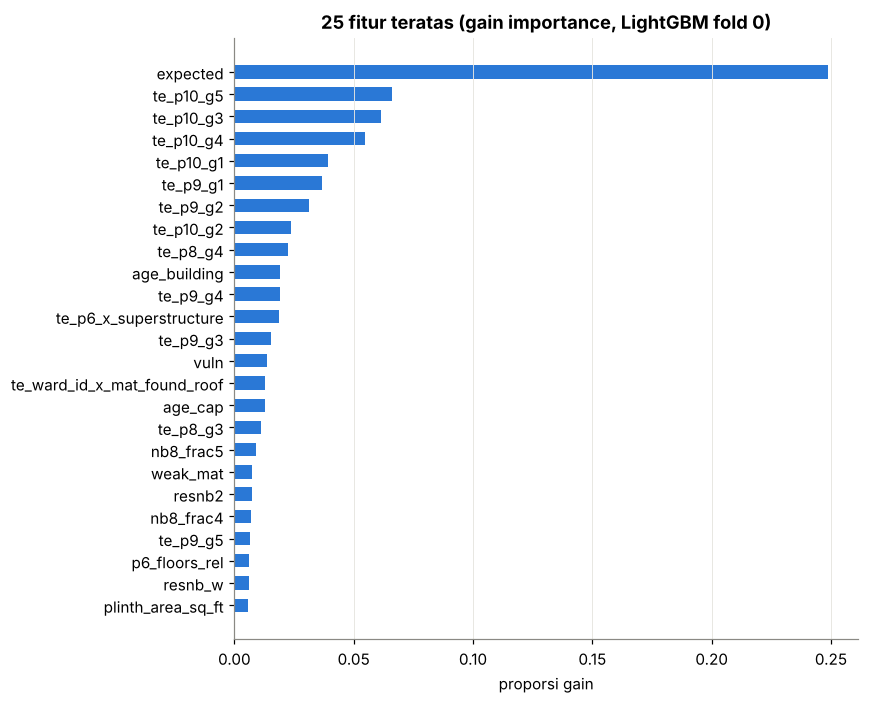

In [4]:
top = imp.head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top.index, top.values, color=ACCENT, height=0.6)
ax.set_title('25 fitur teratas (gain importance, LightGBM fold 0)'); ax.set_xlabel('proporsi gain'); ax.grid(axis='y', visible=False)
savefig('feature_importance')

## 5. Normalisasi / Transformasi Data (`ColumnTransformer`)

- **Model pohon**: numerik `passthrough` (pohon invarian terhadap transformasi monoton), kategori `OrdinalEncoder`.
- **Model linear**: `SimpleImputer(median)` → `log1p` untuk kolom miring (luas, tinggi, cacah) → `StandardScaler`,
  kategori `OneHotEncoder`. Semua di-*fit* hanya pada data latih fold.

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('target_features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,n_splits,5
,smoothing,20
,random_state,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transforme

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('target_features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,n_splits,5
,smoothing,20
,random_state,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skew', ...), ('num', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``tran

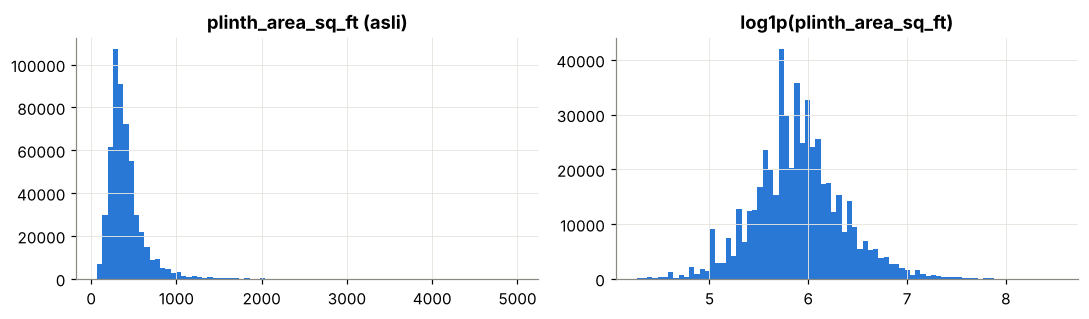

In [5]:
display(build_pipeline(lgb.LGBMClassifier(), keep=FEATS))
display(build_pipeline(LogisticRegression(), kind='linear', keep=FEATS))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(X.plinth_area_sq_ft, bins=80, color=ACCENT); axes[0].set_title('plinth_area_sq_ft (asli)')
axes[1].hist(np.log1p(X.plinth_area_sq_ft), bins=80, color=ACCENT); axes[1].set_title('log1p(plinth_area_sq_ft)')
savefig('transformasi_log1p')

## 6. Konstruksi Model

| Model | Pipeline |
|---|---|
| `logreg_ovr` | regresi logistik **One-vs-Rest** (5 classifier biner), preprocessor linear |
| `lgbm` | LightGBM multiclass, preprocessor pohon |
| `xgb` | XGBoost multiclass (hist), preprocessor pohon |

Jumlah pohon LightGBM dipilih dengan early stopping di fold 0 (tahap 10). Supaya waktu wajar di CPU 4 core,
regresi logistik divalidasi pada subsampel stratified 150 ribu baris dan XGBoost memakai learning rate 0,15.

In [6]:
N_EST = tune_n_estimators(X, y, {**LGBM_PARAMS, 'n_jobs': N_JOBS}, FOLDS)
LGBM_FINAL = {**LGBM_PARAMS, 'n_estimators': N_EST, 'n_jobs': N_JOBS}
print('n_estimators LightGBM (early stopping fold 0):', N_EST)

n_estimators LightGBM (early stopping fold 0): 399


In [7]:
OOF = {}
def run_cv(name, pipe, Xs=X, ys=y, folds=FOLDS):
    t = time.time()
    P = oof_proba(pipe, Xs, ys, folds)
    OOF[name] = (P, ys, folds)
    print(f'{name:11s} OOF Macro F1 (argmax) = {macro_f1(ys, P.argmax(1) + 1):.5f}  ({time.time()-t:.0f}s)')

# regresi logistik One-vs-Rest pada subsampel stratified
rng = np.random.default_rng(SEED)
sub_idx = np.sort(np.concatenate([rng.choice(np.where(y == g)[0], int(min(150_000, len(y) // 2) * (y == g).mean()), replace=False) for g in GRADES]))
X_sub, y_sub = X.iloc[sub_idx].reset_index(drop=True), y[sub_idx]
run_cv('logreg_ovr', build_pipeline(OneVsRestClassifier(LogisticRegression(max_iter=300, C=0.5)), kind='linear', keep=FEATS),
       X_sub, y_sub, make_folds(X_sub, y_sub))

logreg_ovr  OOF Macro F1 (argmax) = 0.54427  (381s)


In [8]:
run_cv('lgbm', build_pipeline(lgb.LGBMClassifier(**LGBM_FINAL), keep=FEATS))

lgbm        OOF Macro F1 (argmax) = 0.59316  (1105s)


In [9]:
XGB_PARAMS = dict(n_estimators=250, learning_rate=0.15, max_depth=8, min_child_weight=5, subsample=0.8,
                  colsample_bytree=0.6, tree_method='hist', objective='multi:softprob', random_state=SEED, n_jobs=N_JOBS)
run_cv('xgb', build_pipeline(xgb.XGBClassifier(**XGB_PARAMS), keep=FEATS))

xgb         OOF Macro F1 (argmax) = 0.59000  (919s)


## 7. Model Selection

Perbandingan Macro F1 OOF dan F1 per grade. Gerbang derau (skill `noise-floor`): selisih di bawah 2 × SE bootstrap
dianggap tidak bermakna. Regresi logistik dinilai pada subsampelnya sendiri, jadi angkanya hanya pembanding kasar.

In [10]:
rows = {}
for k, (P, ys, _) in OOF.items():
    p = P.argmax(1) + 1
    cm = confusion_matrix(ys, p, labels=GRADES)
    f1g = 2 * np.diag(cm) / (cm.sum(0) + cm.sum(1))
    rows[k] = {'macro_f1_argmax': macro_f1(ys, p), **{f'f1_g{g}': v for g, v in zip(GRADES, f1g)}}
RINGKAS = pd.DataFrame(rows).T.sort_values('macro_f1_argmax', ascending=False)
display(RINGKAS.round(4))
se_oof = bootstrap_se(y, OOF['lgbm'][0].argmax(1) + 1, len(y), B=100)
se_pub = bootstrap_se(y, OOF['lgbm'][0].argmax(1) + 1, int(0.3 * len(test)), B=200)
GATE_OOF = 2 * se_oof
print(f'gerbang OOF 2xSE = {GATE_OOF:.5f} | gerbang papan publik 2xSE (asumsi 30% test) = {2*se_pub:.5f}')

,macro_f1_argmax,f1_g1,f1_g2,f1_g3,f1_g4,f1_g5
lgbm,0.5932,0.7026,0.4507,0.4808,0.5629,0.7687
xgb,0.5900,0.6979,0.4464,0.4778,0.5607,0.7672
logreg_ovr,0.5443,0.6607,0.3744,0.4253,0.5156,0.7453


gerbang OOF 2xSE = 0.00156 | gerbang papan publik 2xSE (asumsi 30% test) = 0.00399


## 10. Optimalisasi Performa Model

1. **Jumlah pohon** dipilih dengan early stopping (di atas).
2. **Bobot kelas untuk Macro F1**: argmax memaksimalkan akurasi dan cenderung memilih grade mayoritas.
   Probabilitas dikalikan bobot per kelas yang dicari dengan *coordinate ascent* di OOF. Efeknya diukur jujur
   dengan *cross-fitting* (bobot dicari di 4 fold, diuji di fold ke-5).
3. **Ensemble** LightGBM + XGBoost hanya dipakai kalau kenaikannya melewati gerbang derau.

> Tahap 10 ditempatkan sebelum evaluasi akhir karena model final memakai hasil optimasi ini.

In [11]:
P_l, P_x = OOF['lgbm'][0], OOF['xgb'][0]
best = max(((wl, macro_f1(y, (wl * P_l + (1 - wl) * P_x).argmax(1) + 1)) for wl in np.arange(0, 1.01, 0.1)), key=lambda t: t[1])
P_blend = best[0] * P_l + (1 - best[0]) * P_x
HASIL = pd.DataFrame({
    'argmax': {'lgbm': macro_f1(y, P_l.argmax(1) + 1), 'xgb': macro_f1(y, P_x.argmax(1) + 1), 'blend': macro_f1(y, P_blend.argmax(1) + 1)},
    'bobot_kelas_crossfit': {'lgbm': crossfit_macro_f1(P_l, y, FOLDS), 'xgb': crossfit_macro_f1(P_x, y, FOLDS),
                             'blend': crossfit_macro_f1(P_blend, y, FOLDS)}})
display(HASIL.round(5))
gain = HASIL.loc['blend', 'bobot_kelas_crossfit'] - HASIL.loc['lgbm', 'bobot_kelas_crossfit']
print(f'bobot blend LightGBM = {best[0]:.1f} | kenaikan blend vs LightGBM = {gain:+.5f} (gerbang {GATE_OOF:.5f})')
print('Model final: LightGBM' + (' (blend tidak melewati gerbang)' if gain <= GATE_OOF else ' -- blend melewati gerbang, tetapi pipeline final tetap satu model agar sederhana'))
W_FINAL = fit_class_weights(P_l, y)
PRED_OOF = (P_l * W_FINAL).argmax(1) + 1
print('bobot kelas final (relatif grade 1):', np.round(W_FINAL, 3))

,argmax,bobot_kelas_crossfit
lgbm,0.59316,0.59703
xgb,0.59000,0.59462
blend,0.59358,0.59792


bobot blend LightGBM = 0.7 | kenaikan blend vs LightGBM = +0.00089 (gerbang 0.00156)
Model final: LightGBM (blend tidak melewati gerbang)


bobot kelas final (relatif grade 1): [1.    1.5   1.375 1.25  1.   ]


## 8. Evaluasi Model

Model final: pipeline LightGBM + bobot kelas. Macro F1 di bawah memakai bobot yang dicari di seluruh OOF
(sedikit optimistis); angka *crossfit* di tabel tahap 10 adalah perkiraan yang lebih jujur.

In [12]:
print(classification_report(y, PRED_OOF, labels=GRADES, digits=4))
CM = confusion_matrix(y, PRED_OOF, labels=GRADES)
print(CM)
F1_GRADE = pd.Series(2 * np.diag(CM) / (CM.sum(0) + CM.sum(1)), index=[f'G{g}' for g in GRADES])
print('Macro F1 OOF (bobot di seluruh OOF):', round(macro_f1(y, PRED_OOF), 5),
      '| crossfit:', round(HASIL.loc['lgbm', 'bobot_kelas_crossfit'], 5))
print('Grade tersulit:', F1_GRADE.idxmin(), round(F1_GRADE.min(), 4))

              precision    recall  f1-score   support

           1     0.7124    0.6710    0.6911     55170
           2     0.4439    0.5049    0.4724     61080
           3     0.4753    0.4967    0.4858     95488
           4     0.5622    0.5804    0.5711    128691
           5     0.7942    0.7381    0.7651    193036

    accuracy                         0.6232    533465
   macro avg     0.5976    0.5982    0.5971    533465
weighted avg     0.6326    0.6232    0.6271    533465



[[ 37020  12498   3026   1547   1079]
 [  7982  30837  14971   4732   2558]
 [  3698  15782  47428  20460   8120]
 [  1570   5739  21527  74689  25166]
 [  1693   4607  12832  31433 142471]]
Macro F1 OOF (bobot di seluruh OOF): 0.5971 | crossfit: 0.59703
Grade tersulit: G2 0.4724


## 9. Visualisasi Hasil

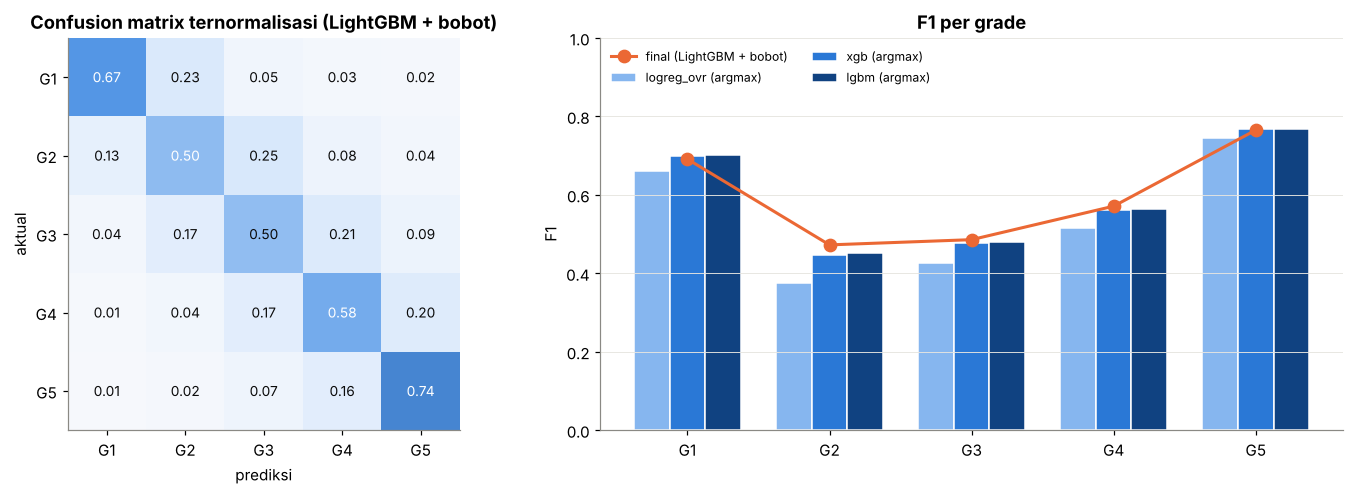

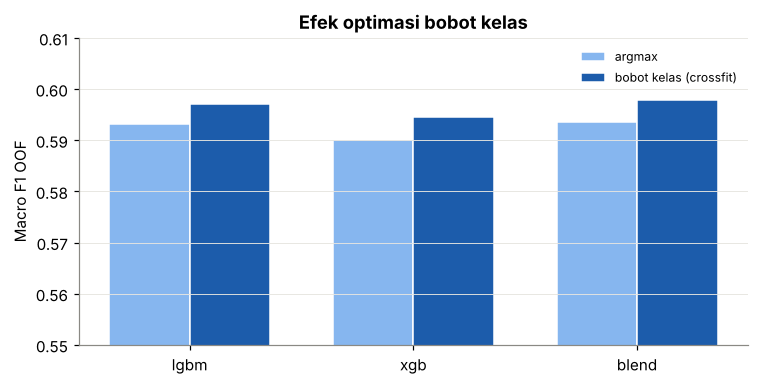

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.3]})
cmn = CM / CM.sum(1, keepdims=True)
ax = axes[0]
ax.imshow(cmn, cmap=mpl.colors.LinearSegmentedColormap.from_list('b', ['#f7f9fd', '#cde2fb', '#5598e7', '#104281']), vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', color='white' if cmn[i, j] > 0.5 else '#0b0b0b', fontsize=9)
ax.set_xticks(range(5), [f'G{g}' for g in GRADES]); ax.set_yticks(range(5), [f'G{g}' for g in GRADES])
ax.set_xlabel('prediksi'); ax.set_ylabel('aktual'); ax.set_title('Confusion matrix ternormalisasi (LightGBM + bobot)'); ax.grid(False)
ax = axes[1]
x = np.arange(5); wbar = 0.25; cols = ['#86b6ef', '#2a78d6', '#104281']
for i, k in enumerate(['logreg_ovr', 'xgb', 'lgbm']):
    ax.bar(x + (i - 1) * wbar, RINGKAS.loc[k, [f'f1_g{g}' for g in GRADES]].values, wbar, color=cols[i], label=f'{k} (argmax)', edgecolor='white')
ax.plot(x, F1_GRADE.values, 'o-', color=ACCENT2, lw=2, ms=8, label='final (LightGBM + bobot)')
ax.set_xticks(x, [f'G{g}' for g in GRADES]); ax.set_ylim(0, 1); ax.set_ylabel('F1'); ax.grid(axis='x', visible=False)
ax.set_title('F1 per grade'); ax.legend(fontsize=8, frameon=False, ncol=2, loc='upper left')
savefig('confusion_matrix_f1_per_grade')

fig, ax = plt.subplots(figsize=(7, 3.6))
xx = np.arange(3)
ax.bar(xx - 0.18, HASIL['argmax'].values, 0.36, color='#86b6ef', label='argmax', edgecolor='white')
ax.bar(xx + 0.18, HASIL['bobot_kelas_crossfit'].values, 0.36, color='#1c5cab', label='bobot kelas (crossfit)', edgecolor='white')
ax.set_xticks(xx, HASIL.index); ax.set_ylim(0.55, 0.61); ax.set_ylabel('Macro F1 OOF'); ax.grid(axis='x', visible=False)
ax.set_title('Efek optimasi bobot kelas'); ax.legend(frameon=False, fontsize=8)
savefig('optimasi_bobot_kelas')

### Simpan model final

Pipeline LightGBM di-*fit* ulang di seluruh train dengan bobot kelas final, lalu disimpan ke
`models/pipeline_lgbm.pkl`. Ringkasan metrik disimpan ke `reports/metrics.json`.

In [14]:
final = build_pipeline(lgb.LGBMClassifier(**LGBM_FINAL), keep=FEATS).set_params(model__class_weights=W_FINAL)
final.fit(X, y)
joblib.dump(final, f'{MODEL_DIR}/pipeline_lgbm.pkl', compress=3)
print('ukuran model:', round(os.path.getsize(f'{MODEL_DIR}/pipeline_lgbm.pkl') / 1e6, 1), 'MB')
metrics = {
    'n_estimators': N_EST, 'n_features': len(FEATS), 'features': FEATS,
    'class_weights': [round(float(w), 4) for w in W_FINAL],
    'oof_macro_f1': {k: round(float(v), 5) for k, v in RINGKAS['macro_f1_argmax'].items()},
    'oof_macro_f1_crossfit_class_weights': {k: round(float(v), 5) for k, v in HASIL['bobot_kelas_crossfit'].items()},
    'f1_per_grade_final': {k: round(float(v), 4) for k, v in F1_GRADE.items()},
    'noise_gate_oof': round(float(GATE_OOF), 5),
    'top_features': list(imp.head(10).index),
}
with open('../reports/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print(json.dumps({k: v for k, v in metrics.items() if k != 'features'}, indent=2))
print(f'Total waktu: {(time.time()-T0)/60:.1f} menit')

ukuran model: 25.8 MB
{
  "n_estimators": 399,
  "n_features": 114,
  "class_weights": [
    1.0,
    1.5,
    1.375,
    1.25,
    1.0
  ],
  "oof_macro_f1": {
    "lgbm": 0.59316,
    "xgb": 0.59,
    "logreg_ovr": 0.54427
  },
  "oof_macro_f1_crossfit_class_weights": {
    "lgbm": 0.59703,
    "xgb": 0.59462,
    "blend": 0.59792
  },
  "f1_per_grade_final": {
    "G1": 0.6911,
    "G2": 0.4724,
    "G3": 0.4858,
    "G4": 0.5711,
    "G5": 0.7651
  },
  "noise_gate_oof": 0.00156,
  "top_features": [
    "expected",
    "te_p10_g5",
    "te_p10_g3",
    "te_p10_g4",
    "te_p10_g1",
    "te_p9_g1",
    "te_p9_g2",
    "te_p10_g2",
    "te_p8_g4",
    "age_building"
  ]
}
Total waktu: 56.5 menit
